# RAG Assignment: Baseline Retrieval vs. Cross-Encoder Re-ranking

**Corpus:** *US Chess Federation's Official Rules of Chess, 7th Edition* (free-download edition, revised 21 August 2020)

This notebook implements the two required pipelines over the **same chunked corpus**:

1. **Baseline:** Bi-Encoder dense retrieval → Top 10 → first Top 3 → LLM Answer 1
2. **Advanced:** the same Top 10 → Cross-Encoder re-ranking → new Top 3 → identical LLM prompt → Answer 2

It also performs chess-specific failure-mode testing, records rank changes, compares answers, profiles latency, and validates the assignment constraints.

> Run the cells in order. Keep the measured outputs when submitting the notebook. Write the accompanying report in your own words.


## 0. Install dependencies

Run this once in a fresh environment, then restart the kernel if Jupyter asks you to.


In [1]:
# If the packages are already installed, this cell finishes quickly.
%pip install -q -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


## 1. Imports and configuration

The document's first 12 PDF pages are cover material, update summaries, and the table of contents. Retrieval begins at PDF page 13, where the actual rules start. Near-empty separator pages are removed automatically.


In [27]:
from __future__ import annotations

import os
import re
import statistics
import time
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
from IPython.display import Markdown, display
from sentence_transformers import CrossEncoder, SentenceTransformer

PDF_PATH = Path("US_Chess_RuleBook.pdf")
FIRST_CONTENT_PAGE = 13
LAST_CONTENT_PAGE = None
MIN_PAGE_CHARACTERS = 150

CHUNK_WORDS = 190
CHUNK_OVERLAP_WORDS = 40
TOP_K = 10
CONTEXT_K = 3

BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"

LLM_MODEL = "gemma-4-26b-a4b-it"
print("Using:", LLM_MODEL)
LLM_TEMPERATURE = 0.0

assert PDF_PATH.exists(), f"Missing corpus: {PDF_PATH.resolve()}"
assert TOP_K == 10 and CONTEXT_K == 3

print(f"Corpus: {PDF_PATH.resolve()}")
print(f"Bi-Encoder: {BI_ENCODER_NAME}")
print(f"Cross-Encoder: {CROSS_ENCODER_NAME}")
print(f"LLM: {LLM_MODEL}")


Using: gemma-4-26b-a4b-it
Corpus: D:\IIITH-SEM3\LMA\RAG_Assignment\US_Chess_RuleBook.pdf
Bi-Encoder: sentence-transformers/all-MiniLM-L6-v2
Cross-Encoder: cross-encoder/ms-marco-MiniLM-L-6-v2
LLM: gemma-4-26b-a4b-it


In [35]:
print(LLM_MODEL)

gemma-4-26b-a4b-it


## 2. Extract and clean the PDF

Cleaning removes repeated page headers/footers and isolated page numbers. Page numbers are retained as metadata so every answer can cite its evidence.


In [3]:
REPEATED_HEADER = re.compile(
    r"US Chess Federation.?s Official Rules of Chess,\s*V?\s*7th Edition,\s*8-21-20",
    flags=re.IGNORECASE,
)

def clean_page_text(raw_text: str) -> str:
    """Remove layout noise while preserving headings and paragraph boundaries."""
    text = raw_text.replace("\u00ad", "")
    text = re.sub(r"(?<=\w)-\n(?=\w)", "", text)
    lines = []
    for raw_line in text.splitlines():
        line = " ".join(raw_line.split())
        if not line:
            lines.append("")
            continue
        if re.fullmatch(r"\d{1,3}", line):
            continue
        if REPEATED_HEADER.fullmatch(line):
            continue
        lines.append(line)

    text = "\n".join(lines)
    text = REPEATED_HEADER.sub("", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


document = pymupdf.open(PDF_PATH)
last_page = LAST_CONTENT_PAGE or document.page_count
pages: list[dict[str, Any]] = []

for page_number in range(FIRST_CONTENT_PAGE, last_page + 1):
    raw = document[page_number - 1].get_text("text", sort=True)
    cleaned = clean_page_text(raw)
    if len(cleaned) >= MIN_PAGE_CHARACTERS:
        pages.append({"page": page_number, "text": cleaned})

print(f"PDF pages: {document.page_count}")
print(f"Content pages retained: {len(pages)}")
print(f"Extracted characters: {sum(len(p['text']) for p in pages):,}")
print("\nPreview:\n", pages[0]["text"][:1_200])


PDF pages: 139
Content pages retained: 126
Extracted characters: 405,752

Preview:
 Chapter 1: US Chess Federation’s
Official Rules of Chess

US Chess Section
1. Introduction
1A. Scope.

Most problems concerning rules that may arise during a chess game are covered in this book. However, the rules of
chess cannot and should not regulate all possible situations. In situations not explicitly covered, the tournament
director can usually reach a fair decision by considering similar cases and applying their principles analogously. The
United States Chess Federation (US Chess) presumes that its tournament directors have the competence, sound
judgment, and absolute objectivity needed to arrive at fair and logical solutions to problems not specifically treated
by these rules.
1B. Validity.

US Chess play shall be governed by these rules of chess and by all US Chess procedures and policies. World Chess
Federation (Federation Internationale des Echecs, or FIDE) rules shall not be used unless spec

## 3. Chunk the corpus

Chunks use fixed word windows **within each page**, so they never lose page provenance. Overlap protects facts near boundaries. Stable IDs such as `P028-C02` make rank shifts auditable.


In [4]:
def chunk_pages(
    page_records: list[dict[str, Any]],
    chunk_words: int = CHUNK_WORDS,
    overlap_words: int = CHUNK_OVERLAP_WORDS,
) -> list[dict[str, Any]]:
    if not 0 <= overlap_words < chunk_words:
        raise ValueError("Overlap must be non-negative and smaller than chunk size.")

    step = chunk_words - overlap_words
    output: list[dict[str, Any]] = []

    for record in page_records:
        words = record["text"].split()
        local_index = 1
        for start in range(0, len(words), step):
            window = words[start : start + chunk_words]
            if len(window) < 45 and start > 0:
                break
            output.append(
                {
                    "chunk_id": f"P{record['page']:03d}-C{local_index:02d}",
                    "page": record["page"],
                    "text": " ".join(window),
                    "word_count": len(window),
                }
            )
            local_index += 1
            if start + chunk_words >= len(words):
                break
    return output


chunks = chunk_pages(pages)
chunk_frame = pd.DataFrame(chunks)

assert chunks, "No chunks were created."
assert chunk_frame["chunk_id"].is_unique
assert chunk_frame["word_count"].max() <= CHUNK_WORDS

display(chunk_frame.head(3))
print(f"Total chunks: {len(chunks)}")
print(
    f"Words/chunk — min: {chunk_frame.word_count.min()}, "
    f"median: {int(chunk_frame.word_count.median())}, "
    f"max: {chunk_frame.word_count.max()}"
)


,chunk_id,page,text,word_count
0,P013-C01,13,Chapter 1: US Chess Federation’s Official Rule...,190
1,P013-C02,13,"than US Chess rules, see Chapter 14, Internati...",190
2,P013-C03,13,"But there are rare occasions, especially when ...",189


Total chunks: 484
Words/chunk — min: 37, median: 190, max: 190


## 4. Bi-Encoder index and baseline retrieval

The Bi-Encoder independently embeds every chunk and the query. Because embeddings are L2-normalized, the dot product below is cosine similarity. For this single PDF, an exact NumPy vector index is clearer than adding a database dependency.


In [5]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME)

chunk_embeddings = bi_encoder.encode(
    chunk_frame["text"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

assert chunk_embeddings.shape[0] == len(chunks)
print("Embedding matrix:", chunk_embeddings.shape)


def baseline_retrieve(query: str, top_k: int = TOP_K) -> list[dict[str, Any]]:
    """Return the Top K chunks by dense cosine similarity."""
    query_vector = bi_encoder.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True,
    )[0]
    scores = chunk_embeddings @ query_vector
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []
    for rank, index in enumerate(top_indices, start=1):
        item = chunks[int(index)].copy()
        item.update({"baseline_rank": rank, "bi_score": float(scores[index])})
        results.append(item)
    return results


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Embedding matrix: (484, 384)


## 5. Cross-Encoder re-ranking

The Cross-Encoder receives each `(query, candidate chunk)` pair jointly. It only scores the baseline Top 10; therefore it cannot recover a relevant chunk missing from those ten candidates.


In [6]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME)


def rerank_candidates(
    query: str,
    candidates: list[dict[str, Any]],
) -> list[dict[str, Any]]:
    """Re-score exactly the baseline candidates, then sort descending."""
    pairs = [(query, candidate["text"]) for candidate in candidates]
    scores = np.asarray(cross_encoder.predict(pairs, show_progress_bar=False)).reshape(-1)

    reranked = []
    for candidate, score in zip(candidates, scores):
        item = candidate.copy()
        item["cross_score"] = float(score)
        reranked.append(item)

    reranked.sort(key=lambda item: item["cross_score"], reverse=True)
    for rank, item in enumerate(reranked, start=1):
        item["reranked_rank"] = rank

    assert {x["chunk_id"] for x in reranked} == {x["chunk_id"] for x in candidates}
    return reranked


C:\Apps\Python\Python-3.14.5\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\91868\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

C:\Apps\Python\Python-3.14.5\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\91868\.cache\huggingface\hub\models--cross-encoder--ms-marco-MiniLM-L-6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

## 6. One shared LLM prompt

Both answers use the exact same function, prompt, model, temperature, and number of context chunks. Only the identities/order of the selected Top 3 chunks differ.

Set the key before running this section:

```powershell
$env:GEMINI_API_KEY="your-key"
```


In [12]:
PROMPT_TEMPLATE = """You are answering a question about the US Chess Federation's Official Rules of Chess.

Use only the context below.
- Give a concise, direct answer.
- Preserve exceptions, timing conditions, and director discretion.
- Cite supporting evidence using the supplied [chunk_id, PDF page] labels.
- If the context is insufficient, say: "The provided context is insufficient."

CONTEXT
{context}

QUESTION
{question}

ANSWER
"""


def build_prompt(question: str, selected_chunks: list[dict[str, Any]]) -> str:
    context = "\n\n".join(
        f"[{item['chunk_id']}, PDF page {item['page']}]\n{item['text']}"
        for item in selected_chunks
    )
    return PROMPT_TEMPLATE.format(context=context, question=question)


def generate_answer(question: str, selected_chunks: list[dict[str, Any]]) -> str:
    """Generate one grounded answer with Gemini using the shared prompt."""
    api_key = os.getenv("GEMINI_API_KEY")
    if not api_key:
        return (
            "[GENERATION SKIPPED: set GEMINI_API_KEY, restart the kernel if needed, "
            "and rerun this cell plus the answer cells.]"
        )

    from google import genai
    from google.genai import types

    client = genai.Client(api_key=api_key)
    from google.genai import errors

    # Retry temporary overloads without changing the model or prompt.
    for attempt in range(4):
        try:
            response = client.models.generate_content(
                model=LLM_MODEL,
                contents=build_prompt(question, selected_chunks),
                config=types.GenerateContentConfig(temperature=LLM_TEMPERATURE),
            )
            if not response.text:
                raise RuntimeError("Gemini returned no answer text.")
            return response.text.strip()
        except errors.APIError as error:
            if error.code not in (429, 500, 502, 503, 504) or attempt == 3:
                raise
            delay = 5 * (2 ** attempt)
            print(f"Gemini temporarily unavailable; retrying in {delay} seconds.")
            time.sleep(delay)


## 7. Chess-specific stress-test queries

The bank deliberately targets the requested failure modes: keyword distractors, exceptions, negation, and special constraints. Evidence phrases identify the intended rule chunk without using its rank. We first test retrieval for every query and call the LLM only for cases that actually demonstrate the required rank shift.


In [29]:
STRESS_TESTS = [
    {
        "test_id": "Q1",
        "failure_type": "Exception / variation",
        "query": (
            "A player intends to castle but touches the rook before the king. "
            "Must the rook be moved, or may the player still castle under an allowed variation?"
        ),
        "evidence_phrases": ["rook touched first", "there is no penalty"],
    },
    {
        "test_id": "Q2",
        "failure_type": "Negation / role constraint",
        "query": (
            "During time pressure, should the tournament director point out an illegal move "
            "without a player making a claim?"
        ),
        "evidence_phrases": ["should not call attention", "only the players"],
    },
    {
        "test_id": "Q3",
        "failure_type": "Corner case / event ordering",
        "query": "Does checkmate count when both players have no time left?",
        "evidence_phrases": ["checkmate and both flags down", "prior to a checkmate"],
    },
    {
        "test_id": "Q4",
        "failure_type": "Exception / director discretion",
        "query": (
            "Does arriving more than one hour late always lose the game, even when the "
            "tournament director knows the player was unavoidably delayed?"
        ),
        "evidence_phrases": ["unavoidably delayed", "waive the one-hour"],
    },
    {
        "test_id": "Q5",
        "failure_type": "Keyword distractor / online-vs-OTB",
        "query": (
            "In an online US Chess game, may players use separate physical chess clocks "
            "instead of the time displayed by the host system?"
        ),
        "evidence_phrases": ["not allowed to use separate chess clocks", "host system"],
    },
    {
        "test_id": "Q6",
        "failure_type": "Exception / equipment",
        "query": (
            "After a chess game has started, can its clock ever be replaced, and how must "
            "the replacement be configured?"
        ),
        "evidence_phrases": ["defective clock must be replaced", "set in the same manner"],
    },
    {
        "test_id": "Q7",
        "failure_type": "Constraint / promotion",
        "query": (
            "When promoting, does merely touching an off-board piece force the player to "
            "choose it, or when does that choice become final?"
        ),
        "evidence_phrases": ["not obligated to promote", "touches the promotion square"],
    },
    {
        "test_id": "Q8",
        "failure_type": "Timing / draw offer",
        "query": (
            "May a player withdraw a draw offer made before moving after noticing a strong "
            "move, and may the opponent require the move before deciding?"
        ),
        "evidence_phrases": ["draw offer before moving", "right to require"],
    },
]


def evidence_match(chunk_text: str, phrases: list[str]) -> bool:
    normalized = chunk_text.casefold()
    return all(phrase.casefold() in normalized for phrase in phrases)


def locate_evidence_chunks(phrases: list[str]) -> list[str]:
    return [
        chunk["chunk_id"]
        for chunk in chunks
        if evidence_match(chunk["text"], phrases)
    ]


for test in STRESS_TESTS:
    matches = locate_evidence_chunks(test["evidence_phrases"])
    test["evidence_chunk_ids"] = matches
    print(test["test_id"], "evidence chunks:", matches)

assert all(test["evidence_chunk_ids"] for test in STRESS_TESTS), (
    "At least one evidence phrase pair did not survive cleaning/chunking. "
    "Inspect the printed test ID and adjust its phrases."
)


Q1 evidence chunks: ['P028-C01']
Q2 evidence chunks: ['P029-C02']
Q3 evidence chunks: ['P040-C01']
Q4 evidence chunks: ['P033-C04', 'P034-C02']
Q5 evidence chunks: ['P129-C02', 'P129-C03']
Q6 evidence chunks: ['P022-C01']
Q7 evidence chunks: ['P027-C04']
Q8 evidence chunks: ['P036-C02']


## 8. Retrieval evaluation and rank-shift analysis

A qualifying failure has its evidence at baseline rank **4-10** and the same evidence promoted to re-ranked position **1-3**.


In [30]:
def rank_of_evidence(
    ranked_chunks: list[dict[str, Any]],
    evidence_ids: list[str],
    rank_field: str,
) -> int | None:
    ranks = [
        item[rank_field]
        for item in ranked_chunks
        if item["chunk_id"] in evidence_ids
    ]
    return min(ranks) if ranks else None


retrieval_runs: list[dict[str, Any]] = []
rank_rows: list[dict[str, Any]] = []

for test in STRESS_TESTS:
    start = time.perf_counter()
    baseline = baseline_retrieve(test["query"])
    baseline_seconds = time.perf_counter() - start

    start = time.perf_counter()
    reranked = rerank_candidates(test["query"], baseline)
    rerank_seconds = time.perf_counter() - start

    baseline_rank = rank_of_evidence(
        baseline, test["evidence_chunk_ids"], "baseline_rank"
    )
    reranked_rank = rank_of_evidence(
        reranked, test["evidence_chunk_ids"], "reranked_rank"
    )
    qualifies = (
        baseline_rank is not None
        and 4 <= baseline_rank <= TOP_K
        and reranked_rank is not None
        and reranked_rank <= CONTEXT_K
    )

    retrieval_runs.append(
        {**test, "baseline": baseline, "reranked": reranked}
    )
    rank_rows.append(
        {
            "test_id": test["test_id"],
            "failure_type": test["failure_type"],
            "baseline_evidence_rank": baseline_rank,
            "reranked_evidence_rank": reranked_rank,
            "rank_change": (
                None
                if baseline_rank is None or reranked_rank is None
                else baseline_rank - reranked_rank
            ),
            "baseline_ms": baseline_seconds * 1_000,
            "reranking_ms": rerank_seconds * 1_000,
            "two_stage_total_ms": (baseline_seconds + rerank_seconds) * 1_000,
            "qualifies": qualifies,
        }
    )

rank_results = pd.DataFrame(rank_rows)
display(rank_results)

qualified_ids = rank_results.loc[rank_results["qualifies"], "test_id"].tolist()
print(f"Qualifying failures: {qualified_ids}")


,test_id,failure_type,baseline_evidence_rank,reranked_evidence_rank,rank_change,baseline_ms,reranking_ms,two_stage_total_ms,qualifies
0,Q1,Exception / variation,1.0,1.0,0.0,511.0236,1126.5605,1637.5841,False
1,Q2,Negation / role constraint,NaN,NaN,NaN,24.8131,426.5867,451.3998,False
2,Q3,Corner case / event ordering,10.0,1.0,9.0,19.8043,435.1975,455.0018,True
3,Q4,Exception / director discretion,1.0,1.0,0.0,27.0508,426.6565,453.7073,False
4,Q5,Keyword distractor / online-vs-OTB,1.0,1.0,0.0,23.1497,433.6537,456.8034,False
5,Q6,Exception / equipment,4.0,1.0,3.0,26.4430,437.8418,464.2848,True
6,Q7,Constraint / promotion,1.0,3.0,-2.0,25.9648,409.6574,435.6222,False
7,Q8,Timing / draw offer,1.0,1.0,0.0,20.6496,375.2588,395.9084,False


Qualifying failures: ['Q3', 'Q6']


### Inspect the complete Top 10 rankings

This table proves that both pipelines started with the same candidates and shows exactly how each candidate moved.


In [31]:
def comparison_table(run: dict[str, Any]) -> pd.DataFrame:
    reranked_by_id = {
        item["chunk_id"]: item for item in run["reranked"]
    }
    rows = []
    for item in run["baseline"]:
        reranked_item = reranked_by_id[item["chunk_id"]]
        rows.append(
            {
                "chunk_id": item["chunk_id"],
                "page": item["page"],
                "baseline_rank": item["baseline_rank"],
                "bi_score": item["bi_score"],
                "reranked_rank": reranked_item["reranked_rank"],
                "cross_score": reranked_item["cross_score"],
                "is_reference_evidence": item["chunk_id"] in run["evidence_chunk_ids"],
                "preview": item["text"][:160] + "…",
            }
        )
    return pd.DataFrame(rows).sort_values("reranked_rank")


for run in retrieval_runs:
    print("\n", run["test_id"], "—", run["query"])
    display(comparison_table(run))



 Q1 — A player intends to castle but touches the rook before the king. Must the rook be moved, or may the player still castle under an allowed variation?


,chunk_id,page,baseline_rank,bi_score,reranked_rank,cross_score,is_reference_evidence,preview
0,P028-C01,28,1,0.711867,1,7.990545,True,10I. Castling. For description and further inf...
1,P024-C01,24,2,0.675787,2,5.116133,False,8C1. Castling. Several restrictions on the kin...
2,P023-C03,23,3,0.668530,3,2.752658,False,"the king’s original square (12A, 12B), any squ..."
3,P023-C02,23,4,0.582792,4,2.260682,False,"Except when castling, the king moves to any ad..."
7,P025-C03,25,8,0.470033,5,0.113237,False,move is determined with no possibility of chan...
4,P137-C01,137,5,0.517710,6,-0.689785,False,"3.) Before play begins, both players should in..."
9,P025-C01,25,10,0.443030,7,-1.942176,False,TD TIP: Note that promotion is in no way relat...
6,P023-C01,23,7,0.472230,8,-2.372134,False,7. Definition of the Move 7A. Basic definition...
5,P016-C02,16,6,0.490885,9,-3.617732,False,queen or rook as a major piece. 3E. Other expr...
8,P131-C05,131,9,0.460704,10,-4.955761,False,handle the situations defined in this rule. In...



 Q2 — During time pressure, should the tournament director point out an illegal move without a player making a claim?


,chunk_id,page,baseline_rank,bi_score,reranked_rank,cross_score,is_reference_evidence,preview
2,P028-C02,28,3,0.657810,1,6.047182,False,need to be announced in advanced publicity but...
8,P029-C01,29,9,0.635988,2,4.505461,False,TD TIP: If using increment time control it may...
1,P029-C05,29,2,0.696588,3,4.413354,False,only. In an event in which most games are not ...
6,P138-C03,138,7,0.640331,4,4.323764,False,opponent may press the clock without making a ...
3,P037-C03,37,4,0.655870,5,4.174538,False,"not play the move on the board, stop both cloc..."
0,P138-C04,138,1,0.720988,6,3.733914,False,to speak or otherwise interfere. If a spectato...
5,P061-C03,61,6,0.646763,7,3.117041,False,appoint another director to make rulings invol...
7,P137-C04,137,8,0.639823,8,1.824882,False,player who moves his king adjacent to the oppo...
4,P062-C02,62,5,0.651080,9,0.769426,False,"1C2a, Standard penalty;13I, Refusal to obey ru..."
9,P041-C03,41,10,0.633294,10,-1.363150,False,director who believes the claim is clearly inc...



 Q3 — Does checkmate count when both players have no time left?


...

,chunk_id,page,baseline_rank,bi_score,reranked_rank,cross_score,is_reference_evidence,preview
3,P022-C01,22,4,0.578114,1,5.698268,True,5F6. Same clock used for the entire game. Exce...
1,P121-C03,121,2,0.584919,2,2.313712,False,computer. If the computer is unable to accept ...
6,P049-C04,49,7,0.544810,3,1.408548,False,"such a requirement, unless Black is late arriv..."
4,P121-C02,121,5,0.563169,4,0.861275,False,"its output device, except that displays of mov..."
2,P029-C03,29,3,0.581736,5,0.602002,False,the position as it was at adjournment must be ...
8,P137-C02,137,9,0.535021,6,-1.535770,False,may state at the start of the event the direct...
0,P129-C02,129,1,0.613019,7,-1.644068,False,for any reason shall be scored as losses for p...
5,P046-C01,46,6,0.554954,8,-2.761515,False,suddenly qualify for a prize seems unfair. It ...
7,P136-C03,136,8,0.540532,9,-2.968514,False,in any advance publicity and must also be anno...
9,P022-C03,22,10,0.520823,10,-3.449523,False,"the clock. See also 6A, The first move; 16C, R..."



 Q7 — When promoting, does merely touching an off-board piece force the player to choose it, or when does that choice become final?


,chunk_id,page,baseline_rank,bi_score,reranked_rank,cross_score,is_reference_evidence,preview
1,P025-C04,25,2,0.511906,1,3.866045,False,(5H). If the player has released the pawn on t...
6,P024-C04,24,7,0.442695,2,1.948375,False,advanced a total of exactly three squares from...
0,P027-C04,27,1,0.522525,3,1.648786,True,fails to say j’adoube or I adjust. For instanc...
7,P132-C03,132,8,0.434562,4,-1.943779,False,the pawn to a Queen. The player’s move is comp...
5,P027-C02,27,6,0.446619,5,-2.169470,False,that opponents often insist that they did not ...
8,P027-C03,27,9,0.430668,6,-2.381266,False,capture the first piece touched that can be mo...
3,P118-C02,118,4,0.481152,7,-3.261725,False,"either is entitled to use a special board, but..."
2,P131-C05,131,3,0.499628,8,-3.343617,False,handle the situations defined in this rule. In...
4,P132-C01,132,5,0.462967,9,-4.794151,False,"TD TIP: When permitted by the game software, p..."
9,P129-C04,129,10,0.423701,10,-9.331422,False,"online event, players are strongly advised to ..."



 Q8 — May a player withdraw a draw offer made before moving after noticing a strong move, and may the opponent require the move before deciding?


,chunk_id,page,baseline_rank,bi_score,reranked_rank,cross_score,is_reference_evidence,preview
0,P036-C02,36,1,0.768252,1,7.834372,True,"draw (Rule 14,The Drawn Game); however, a rule..."
1,P036-C03,36,2,0.712704,2,7.508460,False,this manner has the right to require the playe...
2,P036-C01,36,3,0.650415,3,5.681765,False,14B. Agreement. The game is drawn upon agreeme...
5,P026-C03,26,6,0.563801,4,3.840916,False,or insufficient losing chances in sudden death...
4,P130-C02,130,5,0.576916,5,3.785283,False,Agreement. Online games may be drawn upon agre...
9,P041-C02,41,10,0.549075,6,2.202581,False,draw request by the claimant also becomes a dr...
3,P057-C02,57,4,0.606436,7,0.920976,False,that the D player is prohibited from making th...
7,P035-C02,35,8,0.552979,8,0.351331,False,"chances (Variation 14H), …) is also making an ..."
8,P035-C03,35,9,0.552195,9,-0.019037,False,end the game in a draw. If the claim is denied...
6,P055-C04,55,7,0.563443,10,-0.415166,False,"stands. See 14B, Agreement. TD TIP: In the cas..."


In [24]:
from google import genai

client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

for model in client.models.list():
    if "generateContent" in (model.supported_actions or []):
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models/lyria-3-pro-preview
models/l

## 9. Generate Answer 1 and Answer 2

The code selects qualifying cases automatically. If model-version differences produce fewer than two, use the diagnostic table above to refine query wording—do not mislabel a non-failure as a success.


In [32]:
if len(qualified_ids) < 2:
    display(Markdown(
        "### Action required\n"
        f"Only **{len(qualified_ids)}** query/queries currently satisfy the exact "
        "rank 4-10 → Top 3 condition. Inspect the rank table, refine the closest "
        "stress queries, and rerun Sections 8-9 before submission."
    ))

selected_ids = qualified_ids[:2]
selected_runs = [
    run for run in retrieval_runs if run["test_id"] in selected_ids
]

answer_rows: list[dict[str, Any]] = []

for run in selected_runs:
    baseline_top3 = run["baseline"][:CONTEXT_K]
    reranked_top3 = run["reranked"][:CONTEXT_K]

    answer_1 = generate_answer(run["query"], baseline_top3)
    answer_2 = generate_answer(run["query"], reranked_top3)

    answer_rows.append(
        {
            "test_id": run["test_id"],
            "query": run["query"],
            "baseline_context_ids": [x["chunk_id"] for x in baseline_top3],
            "reranked_context_ids": [x["chunk_id"] for x in reranked_top3],
            "answer_1": answer_1,
            "answer_2": answer_2,
        }
    )

    display(Markdown(
        f"### {run['test_id']}: {run['query']}\n\n"
        f"**Baseline Top 3:** {', '.join(x['chunk_id'] for x in baseline_top3)}\n\n"
        f"**Answer 1**\n\n{answer_1}\n\n"
        f"**Re-ranked Top 3:** {', '.join(x['chunk_id'] for x in reranked_top3)}\n\n"
        f"**Answer 2**\n\n{answer_2}"
    ))

answers = pd.DataFrame(answer_rows)


### Q3: Does checkmate count when both players have no time left?

**Baseline Top 3:** P031-C01, P034-C02, P026-C01

**Answer 1**

Checkmate takes priority over a subsequent flag fall [P031-C01, PDF page 31]. Because checkmate or stalemate immediately ends the game, pressing or stopping the clock is not required [P026-C01, PDF page 26]. If it is unclear whether the flag fall or checkmate occurred first, a director who is unable to decide after considering all available evidence shall deny the time claim and rule the checkmate valid [P031-C01, PDF page 31]. However, if a player claims a win by time forfeit before the opponent determines a move delivering checkmate, the time forfeit claim is appropriate [P031-C01, PDF page 31].

**Re-ranked Top 3:** P040-C01, P034-C03, P031-C01

**Answer 2**

Checkmate takes priority over a subsequent flag fall [P031-C01, PDF page 31]. However, in sudden death control, the following conditions apply:

*   **Prior Claim:** If a player points out that both flags are down prior to a checkmate, the game is drawn [P040-C01, PDF page 40].
*   **Unclear Timing:** If it is unclear whether the checkmate or the flag fall occurred first, the director shall deny the time claim and rule the checkmate valid after considering all available evidence, including testimony from players and witnesses [P040-C01, PDF page 40; P031-C01, PDF page 31].
*   **Director Discretion:** If a sudden death game continues with both flags down, the director may rule it a draw to avoid delaying the tournament [P040-C01, PDF page 40].
*   **Exception:** These sudden death rules do not apply to increment time controls of 30 seconds or more [P040-C01, PDF page 40].

Gemini temporarily unavailable; retrying in 5 seconds.


### Q6: After a chess game has started, can its clock ever be replaced, and how must the replacement be configured?

**Baseline Top 3:** P129-C02, P121-C03, P029-C03

**Answer 1**

The provided context is insufficient.

**Re-ranked Top 3:** P022-C01, P121-C03, P049-C04

**Answer 2**

Yes, a clock may be replaced if it is defective (as described in rule 16O) or as provided in rules 5F5 and 14H2a [P022-C01, PDF page 22]. If a defective clock is replaced, the replacement clock must be set in the same manner as the clock being replaced [P022-C01, PDF page 22].

## 10. Robust latency profiling

Model loading and LLM generation are excluded. Each query is warmed up once, then timed repeatedly. Medians reduce sensitivity to occasional system interruptions.


,test_id,baseline_retrieval_ms,cross_encoder_reranking_ms,two_stage_total_ms
0,Q1,22.20,429.04,451.24
1,Q2,17.63,432.63,450.26
2,Q3,15.11,358.72,373.84
3,Q4,20.37,389.59,409.96
4,Q5,16.48,382.99,399.46
5,Q6,16.78,382.18,398.97
6,Q7,17.34,373.43,390.76
7,Q8,21.11,383.95,405.06


,baseline_retrieval_ms,cross_encoder_reranking_ms,two_stage_total_ms
mean_ms,18.38,391.57,409.94


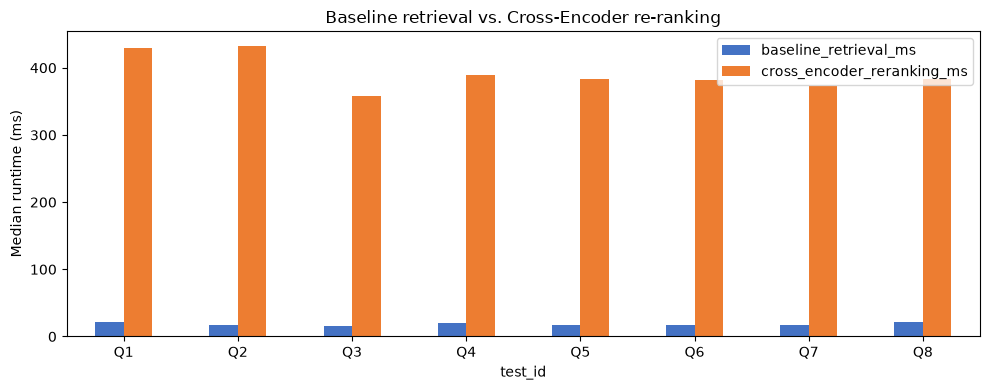

In [33]:
def profile_query(query: str, repeats: int = 5) -> dict[str, float]:
    warm_candidates = baseline_retrieve(query)
    _ = rerank_candidates(query, warm_candidates)

    baseline_samples = []
    rerank_samples = []

    for _ in range(repeats):
        start = time.perf_counter()
        candidates = baseline_retrieve(query)
        baseline_samples.append(time.perf_counter() - start)

        start = time.perf_counter()
        _ = rerank_candidates(query, candidates)
        rerank_samples.append(time.perf_counter() - start)

    baseline_median = statistics.median(baseline_samples)
    rerank_median = statistics.median(rerank_samples)
    return {
        "baseline_retrieval_ms": baseline_median * 1_000,
        "cross_encoder_reranking_ms": rerank_median * 1_000,
        "two_stage_total_ms": (baseline_median + rerank_median) * 1_000,
    }


latency_rows = []
for test in STRESS_TESTS:
    latency_rows.append(
        {"test_id": test["test_id"], **profile_query(test["query"])}
    )

latency = pd.DataFrame(latency_rows)
display(latency.round(2))
display(latency.mean(numeric_only=True).to_frame("mean_ms").T.round(2))

latency.set_index("test_id").plot(
    kind="bar",
    y=["baseline_retrieval_ms", "cross_encoder_reranking_ms"],
    figsize=(10, 4),
    color=["#4472C4", "#ED7D31"],
)
plt.ylabel("Median runtime (ms)")
plt.title("Baseline retrieval vs. Cross-Encoder re-ranking")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Validation Checks

This cell intentionally fails if the recorded run does not yet meet a required condition. Fix the highlighted issue and rerun before submission.


In [36]:
assert TOP_K == 10
assert CONTEXT_K == 3
assert len(chunks) == len(chunk_embeddings)

for run in retrieval_runs:
    baseline_ids = [x["chunk_id"] for x in run["baseline"]]
    reranked_ids = [x["chunk_id"] for x in run["reranked"]]
    assert len(baseline_ids) == TOP_K
    assert len(set(baseline_ids)) == TOP_K
    assert set(baseline_ids) == set(reranked_ids), (
        "Re-ranking must use exactly the baseline Top 10 candidates."
    )

assert len(qualified_ids) >= 2, (
    "The assignment requires at least two cases where evidence moves from "
    "baseline rank 4-10 into the re-ranked Top 3. Refine the stress queries."
)
assert len(answer_rows) >= 2

if os.getenv("GEMINI_API_KEY"):
    assert not any(
        row["answer_1"].startswith("[GENERATION SKIPPED")
        or row["answer_2"].startswith("[GENERATION SKIPPED")
        for row in answer_rows
    )
else:
    raise AssertionError(
        "Set GEMINI_API_KEY and rerun Sections 6, 9, and 11 so Answer 1 and "
        "Answer 2 are present in the submitted notebook."
    )

print("All validation checks passed.")


All validation checks passed.


## 12. Interpretation guide for your report

Write the report yourself using the notebook's actual outputs.

### Architecture comparison

- **Bi-Encoder:** query and chunks are embedded independently; normalized dot product gives cosine similarity. Chunk vectors are precomputed, making retrieval scalable.
- **Cross-Encoder:** each query and candidate are processed jointly with token-level self-attention. This is slower but captures negation, exceptions, roles, and fine-grained relationships more accurately.

### Qualitative and rank-shift analysis

For each selected failure case, report the evidence chunk and baseline → re-ranked position, why the baseline context was incomplete, what Answer 1 omitted or misstated, and how the promoted evidence changed Answer 2.

### Scaling answer

A Cross-Encoder score is query-dependent and cannot be precomputed for each chunk. Applying it to an entire collection of (N) chunks requires roughly (N) expensive joint forward passes for every query. The two-stage system uses fast vector search to obtain ten high-recall candidates and spends Cross-Encoder computation only on those ten pairs.
